# 04 — Models and validation / 模型與驗證

**EN** Baseline ladder: rule → Ridge → LightGBM → deep model (rung 4, trained on Colab). Common yardstick: mean daily Spearman IC with a Newey–West 95% CI over 32 walk-forward folds. The ridge IC is recomputed live from its out-of-fold predictions.

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 模型階梯：規則 → Ridge → LightGBM → 深度模型（第 4 階，在 Colab 訓練）。共同尺度：32 個 walk-forward fold 的平均每日 Spearman IC 與 Newey–West 95% 信賴區間。這裡會用 out-of-fold 預測即時重算 Ridge 的 IC。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

In [2]:
# Validation summary of every rung / 各階模型的驗證摘要
summ = pd.concat([pd.read_csv("reports/models_summary.csv"),
                  pd.read_csv("reports/deep_summary.csv")]).drop_duplicates("model")
display(summ[["model", "ic_mean", "ic_ci_low", "ic_ci_high", "nw_t", "share_positive_folds", "coverage80_mean"]])

,model,ic_mean,ic_ci_low,ic_ci_high,nw_t,share_positive_folds,coverage80_mean
0,rule_carry,0.0425,0.0207,0.0643,3.8229,0.7188,NaN
1,ridge,0.1310,0.1020,0.1599,8.8658,0.9062,0.8005
2,lightgbm,0.1354,0.1125,0.1584,11.5708,0.9688,0.7983
3,deep,0.1217,0.0968,0.1466,9.5818,0.9062,0.8045
4,deep_v2,0.1307,0.1054,0.1560,10.1245,0.9062,0.8095
5,deep_static_only,0.1331,0.1072,0.1590,10.0751,0.9375,0.8035


In [3]:
# Live check: recompute the ridge IC from its out-of-fold predictions / 即時檢查：由 OOF 預測重算 Ridge IC
from crowding.evaluation import evaluate, paired
from crowding.sample import load_sample
dev = load_sample("dev", horizon=7)
preds = {k: pd.read_parquet(f"artifacts/predictions/{k}.parquet") for k in ("rule_carry", "ridge", "lightgbm", "deep_v2")}
res = {k: evaluate(p, dev) for k, p in preds.items()}
print(f"ridge IC live {res['ridge'][0]['ic_mean']:+.4f} vs report "
      f"{summ.set_index('model').loc['ridge', 'ic_mean']:+.4f}")

ridge IC live +0.1310 vs report +0.1310


In [4]:
# Paired comparison: each rung vs the previous one (HAC CI) / 配對比較：每一階對前一階
rows = []
for a, b in (("ridge", "rule_carry"), ("lightgbm", "ridge"), ("deep_v2", "lightgbm")):
    rows.append({"comparison / 比較": f"{a} - {b}", **paired(res[a][1], res[b][1])})
pd.DataFrame(rows)

,comparison / 比較,delta_ic,ci_low,ci_high,nw_t,n_days
0,ridge - rule_carry,0.0885,0.0614,0.1155,6.4132,963
1,lightgbm - ridge,0.0044,-0.0076,0.0165,0.7222,963
2,deep_v2 - lightgbm,-0.0047,-0.0142,0.0048,-0.9692,963


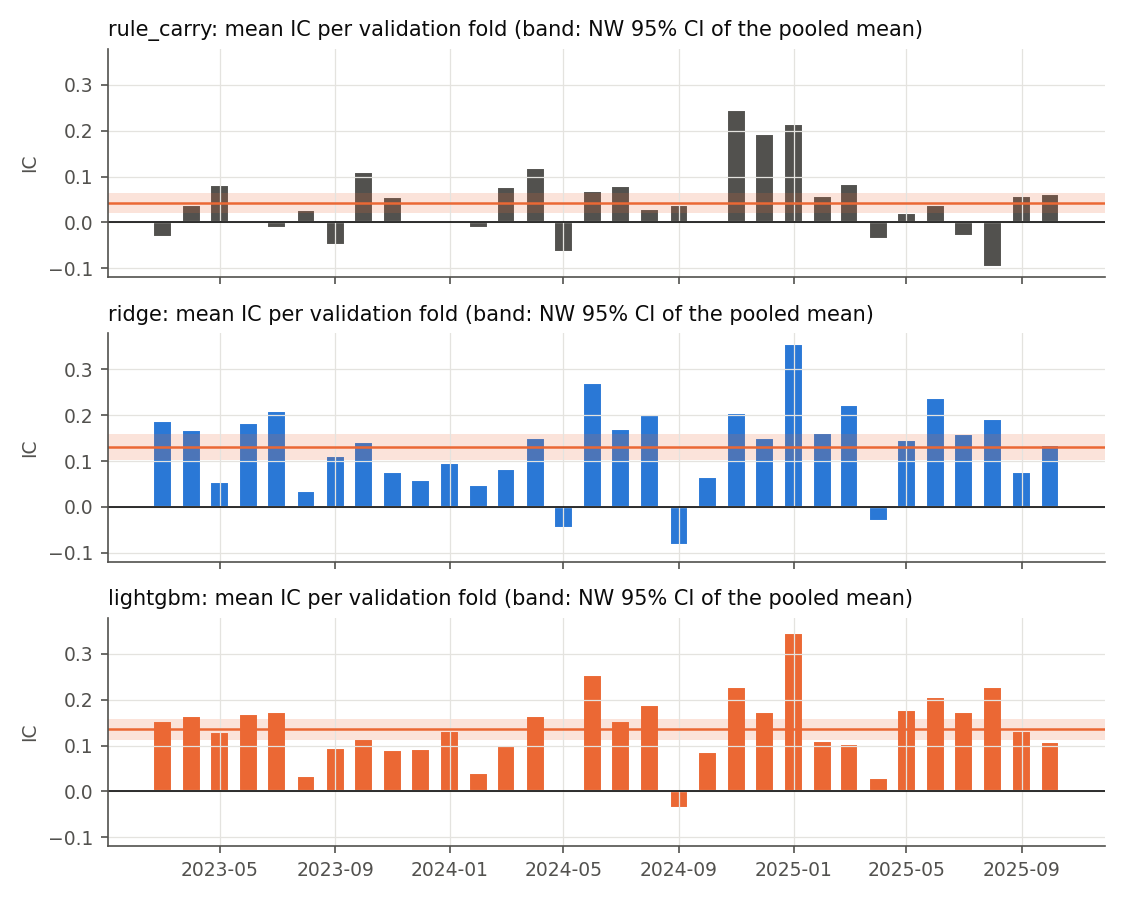

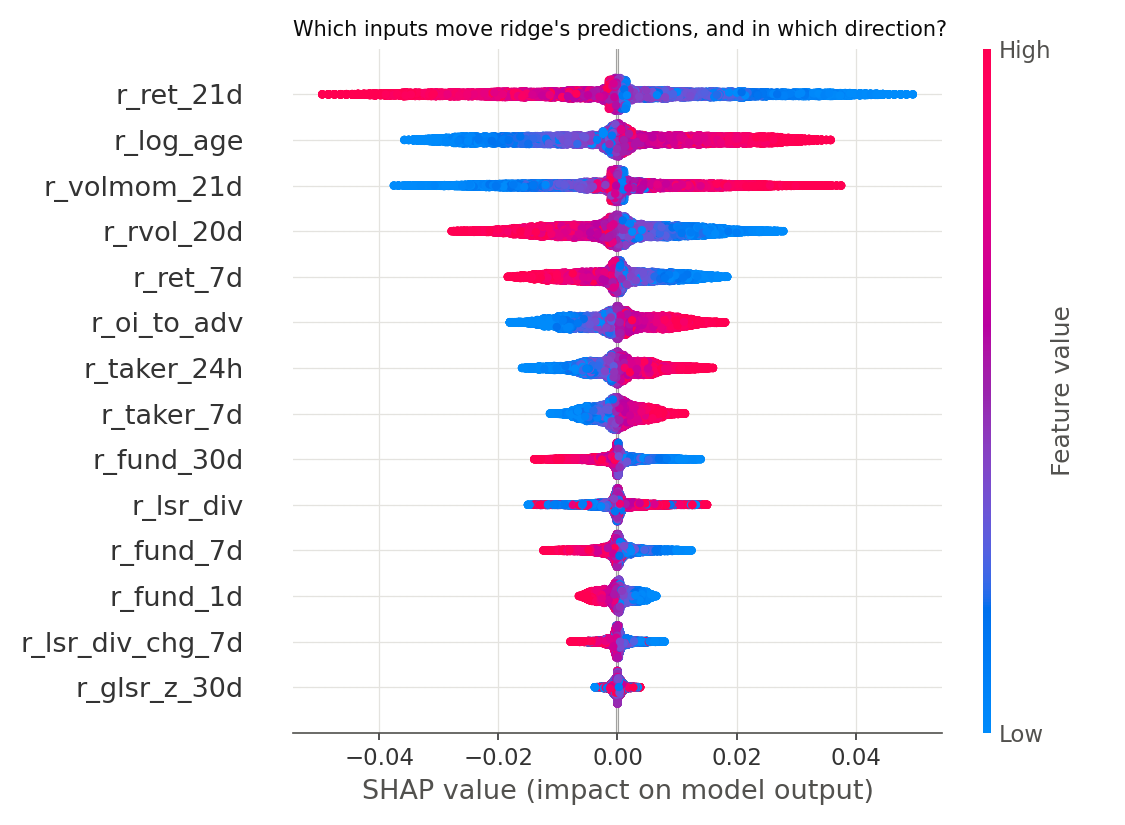

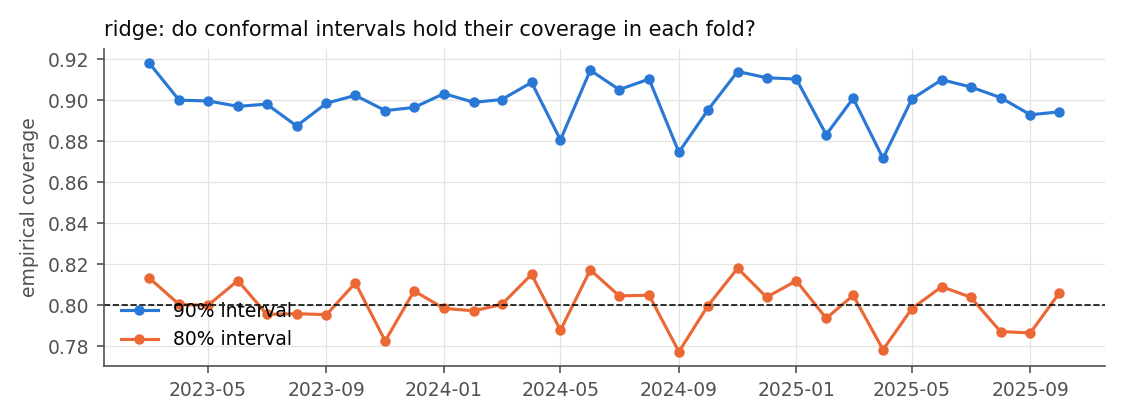

In [5]:
# Fold IC with HAC bands, SHAP of the deployed ridge, conformal coverage / 各 fold IC、SHAP、conformal 覆蓋率
show("models_fold_ic.png"); show("models_shap_ridge.png"); show("models_coverage_ridge.png")

**EN** Ridge is deployed: LightGBM and the deep model are not better by a paired HAC test, and the hourly-sequence ablation adds nothing.

**中文** 部署 Ridge：LightGBM 與深度模型在配對 HAC 檢定下沒有顯著較好，小時序列的消融實驗也顯示沒有增益。